In [1]:
from astropy.io import fits
import numpy as np
from astropy import wcs
import astropy.units as u
import scipy.constants as cst
from astropy.stats import gaussian_fwhm_to_sigma
import astropy.convolution as conv
import datetime
import matplotlib.pyplot as plt
from hitmap_1detector import main_1det
from hitmap_array import main_arrays
from gen_timestreams import main_tod, gen_tod
from src.load_params import load_params, format_duration
from src.hdf5_fcts import save_tod_in_hdf5
from IPython import embed
import numpy as np 
import os
import pickle
from src.scan_fcts import *
from gen_detectors_arrays import gen_detectors_main
import h5py 
import shutil
from astropy.io import fits
from astropy.wcs import WCS

In [3]:
file = 'datasets/pySIDES_from_uchuu_TIM_gaussian_tile0_1.414deg_1.414deg_res20arcsec_R250_full_de_Looze_smoothed_MJy_sr.fits'
cube = fits.getdata(file)
hdr = fits.getheader(file)
reso = (hdr['CDELT1'] * u.Unit(hdr["CUNIT1"]) )
pix_size =  (reso**2).to(u.sr).value 
cube *= pix_size *1e6 # MJy/sr --> Jy

map_area = pix_size * cube.shape[1] * cube.shape[2]

map_size = hdr['NAXIS1']
center = map_size // 2        
path = 'datasets/'


noise = np.zeros((hdr['NAXIS3'], map_size, map_size))
for f in range(hdr['NAXIS3']): 
    noise_level = cube[f,:,:].sum()*pix_size / map_area #noise level in Jy/sr
    # Add white Gaussian noise
    noise[f,:,:] += np.random.normal(loc=0.0, scale=noise_level, size=(map_size, map_size))

w = wcs.WCS(hdr)
#Telescope diameter 
D = 2 #m 

res=676957753280.61 arcsec


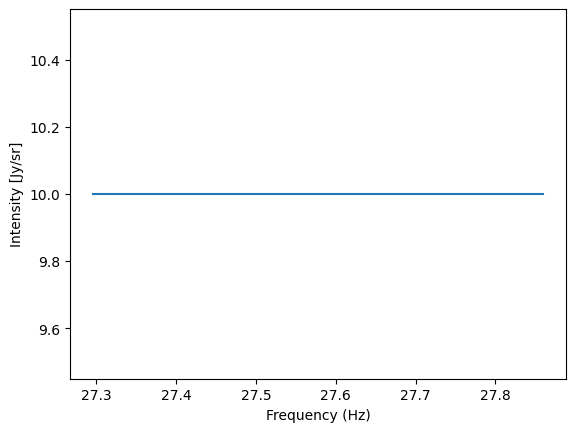

In [4]:
z = np.arange(hdr['NAXIS3'])
freq_list = ( w.swapaxes(0, 2).sub(1).wcs_pix2world(z, 0)[0] * u.Unit(hdr["CUNIT3"]) ).to(u.Hz).value
dnu = (hdr['CDELT3'] * u.Unit(hdr["CUNIT3"]) ).to(u.Hz).value
vdelt = dnu / freq_list * (cst.c*1e-3) #km/sec
fwhm = 1.22 * cst.c / (freq_list * D) * u.rad
sigma = fwhm * gaussian_fwhm_to_sigma
#Omega_beam = (2*np.pi*(sigma)**2).to(u.sr)
res = fwhm.min() / 2
sigma_pix_list = sigma / res

intensity = (res**2).to(u.sr).value*10*vdelt #Jy.km/s

plt.plot(freq_list, intensity / (res**2).to(u.sr).value / vdelt)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Intensity [Jy/sr]')
print(f'res={res.to(u.arcsec):.2f}')


In [7]:
for factor_on_Sigma in (1,1.5,2,2.5): 
            
    cube_1_source = np.zeros((hdr['NAXIS3'], map_size, map_size))
    cube_1_source += noise
    cube_1_source[:, center, center] += intensity / (res**2).to(u.sr).value / vdelt  #Jy/sr

    for f, sigma_pix in enumerate(sigma_pix_list):

        kernel_channel = conv.Gaussian2DKernel(x_stddev=sigma_pix * factor_on_Sigma, x_size=map_size)
        kernel_channel.normalize(mode="peak")
        #size of the beam in pix2
        beam_area_pix2 = np.sum(kernel_channel.array)
        cube_1_source[f] = conv.convolve_fft(cube_1_source[f], kernel_channel, normalize_kernel=True, boundary = 'wrap')

    hdr_out = hdr.copy()
    hdr_out['CDELT2'] = res.to(u.deg).value
    hdr_out['CDELT1'] = res.to(u.deg).value
    hdr_out["DATE"]  = str(datetime.datetime.now())
    hdr_out["BUNIT"] = "Jy/sr"
    hdr_out['CRPIX1'] = center       
    path = 'datasets/'

    hdr_out['CRPIX2'] = center

    # Create HDU and save
    hdu = fits.PrimaryHDU(cube_1_source, header=hdr_out)
    hdul = fits.HDUList([hdu])
    path = 'datasets/'
    savepath = f'cube_1source_with_{factor_on_Sigma}xbigger_sigma_PSF.fits'
    hdul.writeto(path+savepath, overwrite=True)
    print("saved ", path+savepath)
    print('')

    for separation_in_pix in (10,15,20,25):
             
        cube_2_source = np.zeros((hdr['NAXIS3'], map_size, map_size))
        cube_2_source += noise
        cube_2_source[:, center, center-separation_in_pix//2] += intensity / (res**2).to(u.sr).value / vdelt
        cube_2_source[:, center, center+separation_in_pix//2] += intensity / (res**2).to(u.sr).value / vdelt

        for f, sigma_pix in enumerate(sigma_pix_list):

            kernel_channel = conv.Gaussian2DKernel(x_stddev=sigma_pix * factor_on_Sigma, x_size=map_size)
            kernel_channel.normalize(mode="peak")
            #size of the beam in pix2        path = '/home/mvancuyck/Desktop/TIM_analysis/namap/fits_and_hdf5/'

            beam_area_pix2 = np.sum(kernel_channel.array)
            cube_2_source[f] = conv.convolve_fft(cube_2_source[f], kernel_channel, normalize_kernel=True, boundary = 'wrap')

        # Create HDU and save
        hdu = fits.PrimaryHDU(cube_2_source, header=hdr_out)
        hdul = fits.HDUList([hdu])

        savepath = path+f'cube_2sources_separated_by_{res.to(u.arcsec).value*separation_in_pix:.1f}arcsecs_with_{factor_on_Sigma}xbigger_sigma_PSF.fits'
        hdul.writeto(savepath, overwrite=True)
        
        print("saved ",savepath)

saved  datasets/cube_1source_with_1xbigger_sigma_PSF.fits

saved  datasets/cube_2sources_separated_by_6769577532806.1arcsecs_with_1xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_10154366299209.1arcsecs_with_1xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_13539155065612.1arcsecs_with_1xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_16923943832015.2arcsecs_with_1xbigger_sigma_PSF.fits
saved  datasets/cube_1source_with_1.5xbigger_sigma_PSF.fits

saved  datasets/cube_2sources_separated_by_6769577532806.1arcsecs_with_1.5xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_10154366299209.1arcsecs_with_1.5xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_13539155065612.1arcsecs_with_1.5xbigger_sigma_PSF.fits
saved  datasets/cube_2sources_separated_by_16923943832015.2arcsecs_with_1.5xbigger_sigma_PSF.fits
saved  datasets/cube_1source_with_2xbigger_sigma_PSF.fits

saved  datasets/cube_2sources_separated_by_6769